In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset'] = 'dejavuserif'
plt.rcParams['font.size'] = 12

dt = 0.01 # time step size

# Exercise 1

In [2]:
"""Equation of motion for a linear pendulum
for small angles where sin(θ) ~ θ,
and inertial term equals 1

f(θ, ω, t) = - θ - k * ω + A * cos(ϕ * t)
"""
def linear_f(theta, omega, t, **kwargs):

  k = kwargs.get('k', 0.0)
  phi = kwargs.get('phi', 0.66667)
  A = kwargs.get('A', 0.0)

  return - theta - k * omega + A * np.cos(phi * t)


"""Ensure θ is between -π + a and π + a
"""
def limit(theta, a=0.0):

    if theta < -np.pi + a or theta > np.pi + a:
      theta -= 2 * np.pi * np.abs(theta) / theta

    return theta


"""Trapezoidal rule for solving ODEs

For more information see:
https://en.wikipedia.org/wiki/Trapezoidal_rule_(differential_equations)
"""
def trapezoid(theta, omega, t, **kwargs):

  f = kwargs.get('f', linear_f)

  k1a = dt * omega
  k1b = dt * f(theta, omega, t, **kwargs)
  k2a = dt * (omega + k1b)
  k2b = dt * f(theta + k1a, omega + k1b, t + dt, **kwargs)

  theta += (k1a + k2a) / 2
  omega += (k1b + k2b) / 2
  t += dt

  if kwargs.get('angle_wrap', False):
    theta = limit(theta, kwargs.get('shift', 0.0))

  return theta, omega, t


"""Swing the pendulum

Get values of θ and ω for a given initial θ and ω
"""
def swing(theta, omega, **kwargs):

  t = 0.0
  thetas, omegas, nsteps = [], [], []

  integration = kwargs.get('integration', trapezoid)
  nsteps_total = kwargs.get('nsteps', 1000)

  for nstep in range(nsteps_total):

    thetas.append(theta)
    omegas.append(omega)
    nsteps.append(nstep)

    theta, omega, t = integration(theta, omega, t, **kwargs)

  return thetas, omegas, nsteps


"""Plot helper that includes options for labels, colors, and limits
"""
def plot(ax, x, *ys, **kwargs):

  labels = kwargs.get('labels', ['$θ$', '$ω$'])
  cs = kwargs.get('cs', ['c', 'm', 'y'])

  for y, c, label in zip(ys, cs, labels):
    ax.plot(x, y, c, label=label, ms=1)

  xlim = kwargs.get('xlim', None)
  ylim = kwargs.get('ylim', (-np.pi,np.pi))

  if xlim is not None:
    ax.set_xlim(*xlim)
  ax.set_ylim(*ylim)

  if kwargs.get('yax2', False):
    ax2 = ax.twinx()
    ax2.set_ylim(*ylim)
    ax2.set_ylabel('Angular velocity (rad/s)')

  ax.set_xlabel(kwargs.get('xlabel', 'Time (s)'))
  ax.set_ylabel(kwargs.get('ylabel', 'Angle (rad)'))
  ax.set_title(kwargs.get('title', ''))

  if kwargs.get('legend', True):
    ax.legend()


"""Get time from number of steps
"""
def time(steps):
  return np.arange(len(steps)) * dt

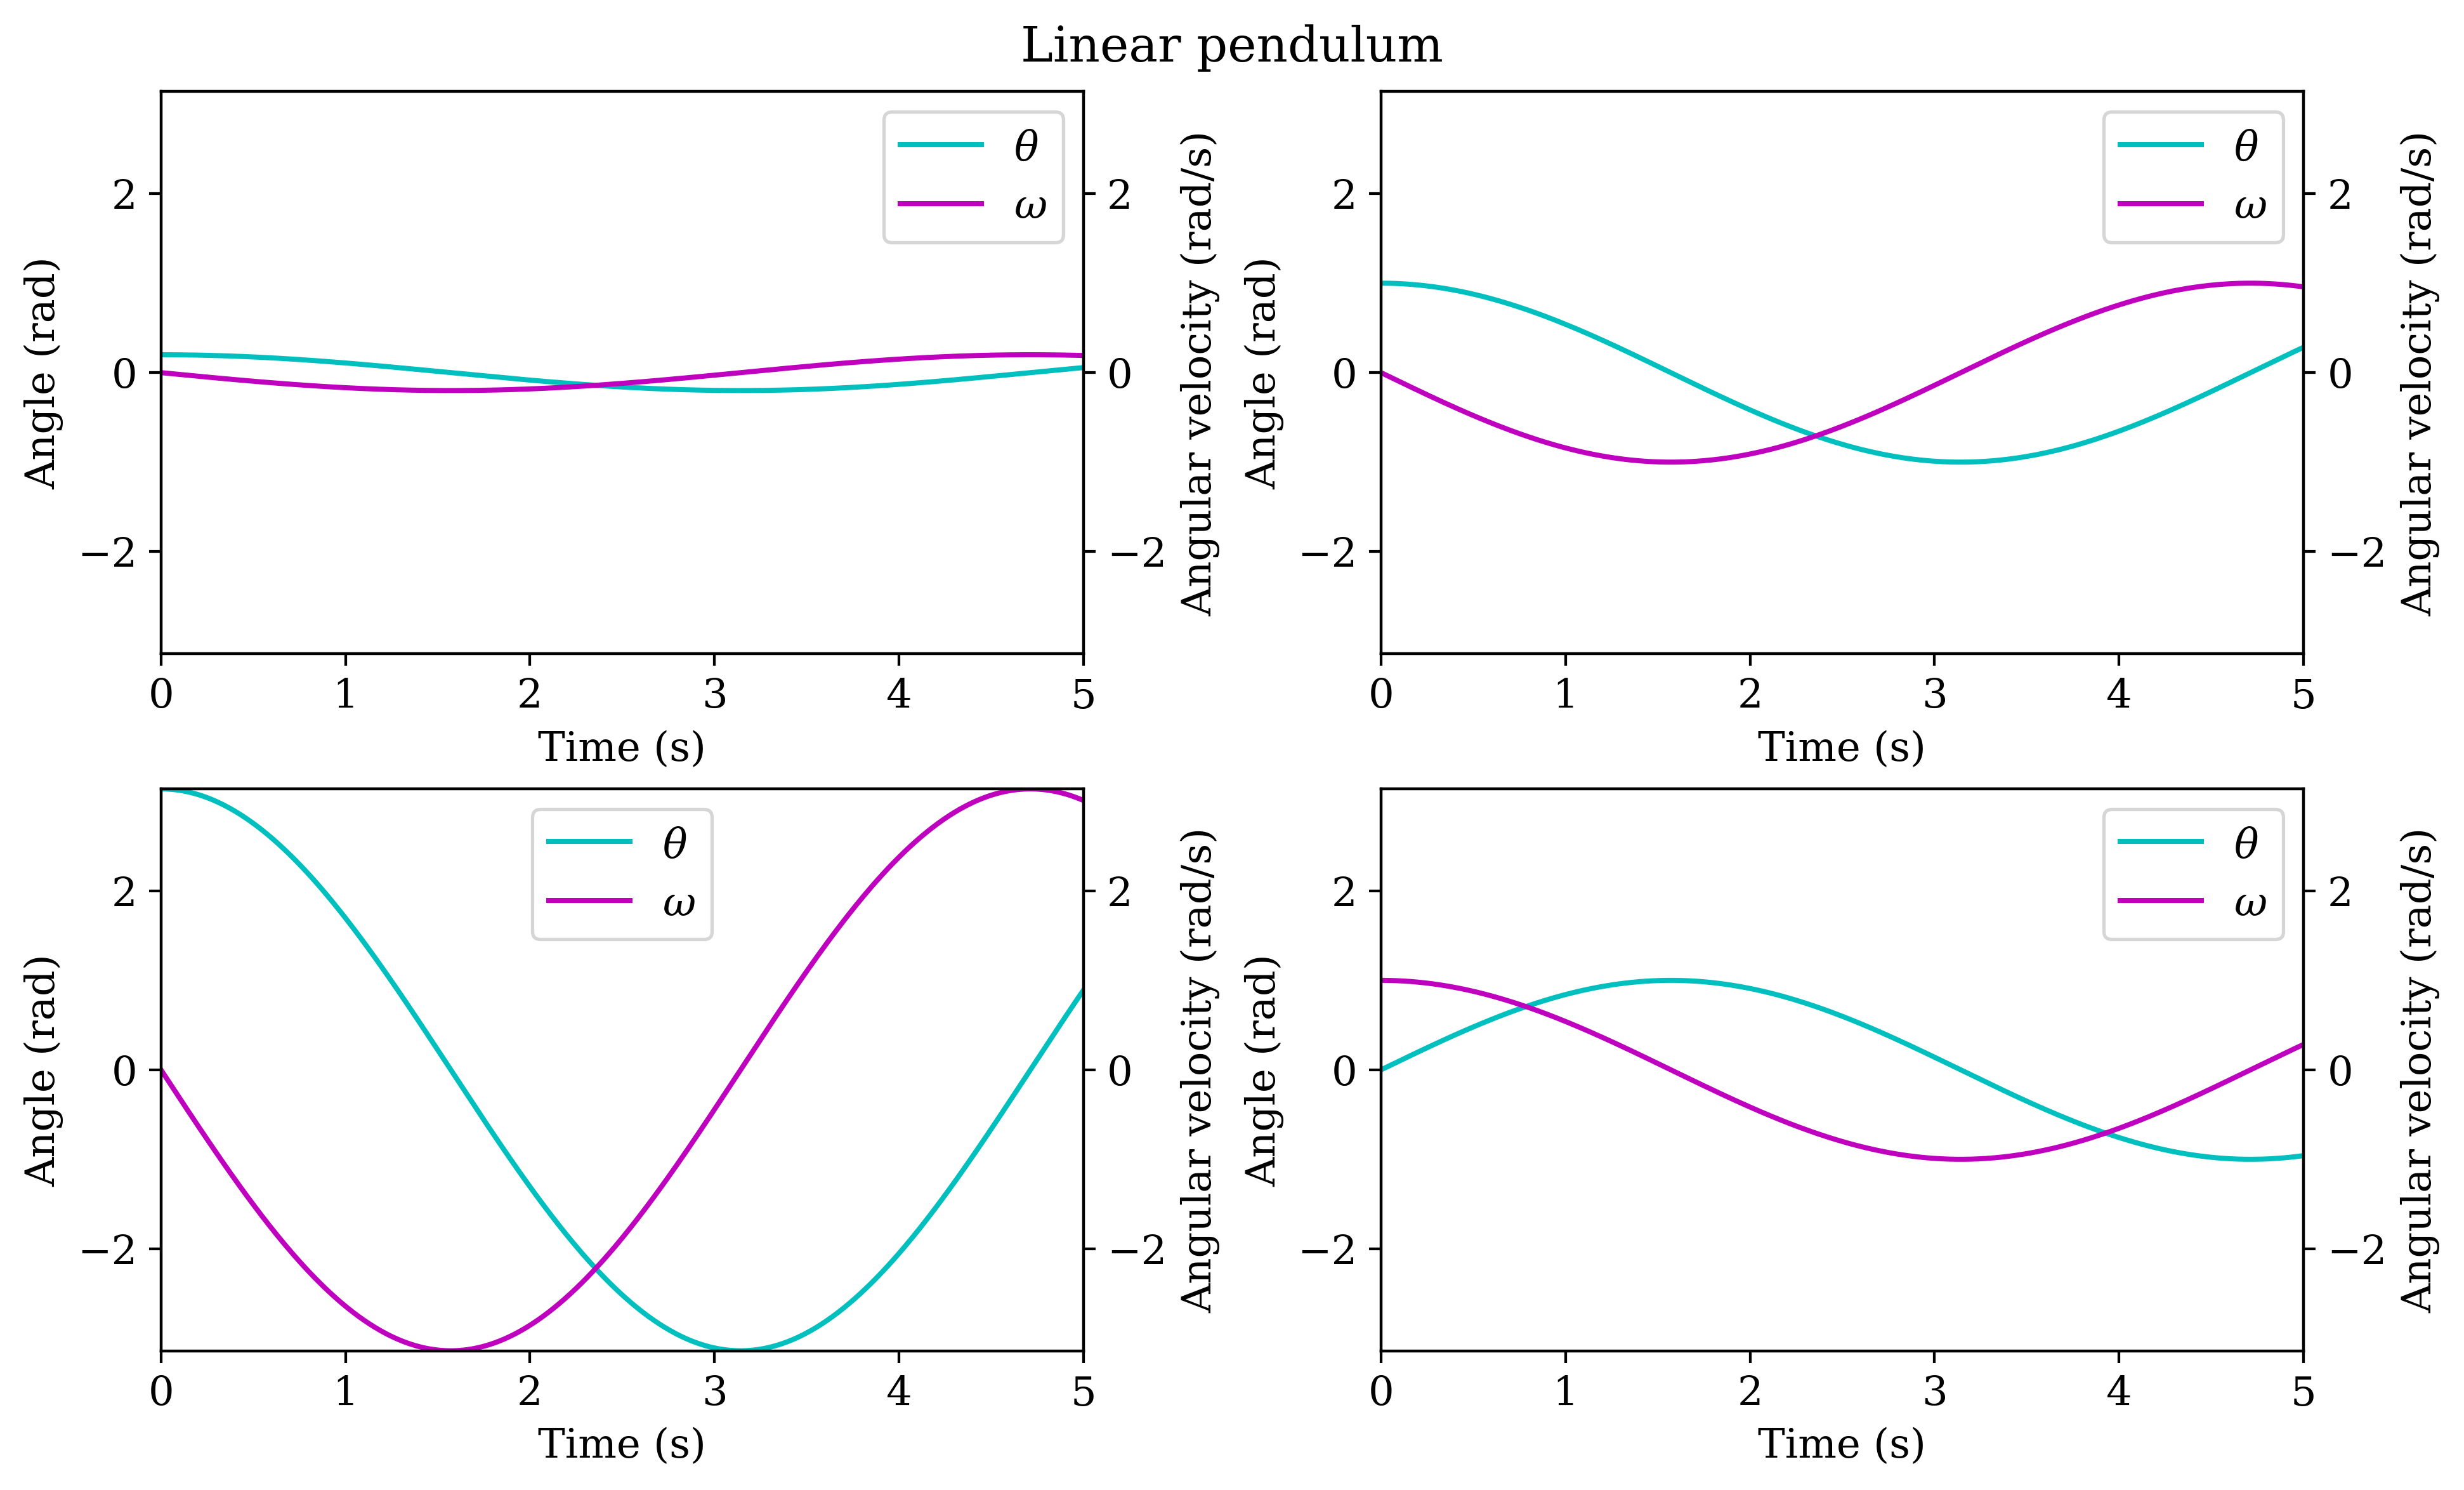

In [3]:
initial_theta = [0.2, 1.0, 3.14, 0.0]
initial_omega = [0.0, 0.0, 0.0, 1.0]

fig, axs = plt.subplots(2, 2, figsize=(10, 6), constrained_layout=True,
                        dpi=384)
fig.suptitle('Linear pendulum')

for theta, omega, ax in zip(initial_theta, initial_omega, axs.flat):
  thetas, omegas, nsteps = swing(theta, omega)

  plot(ax, time(nsteps), thetas, omegas, xlim=(0,5), yax2=True)

plt.savefig('linear_pendulum.png', bbox_inches='tight')
plt.show()

# Exercise 2

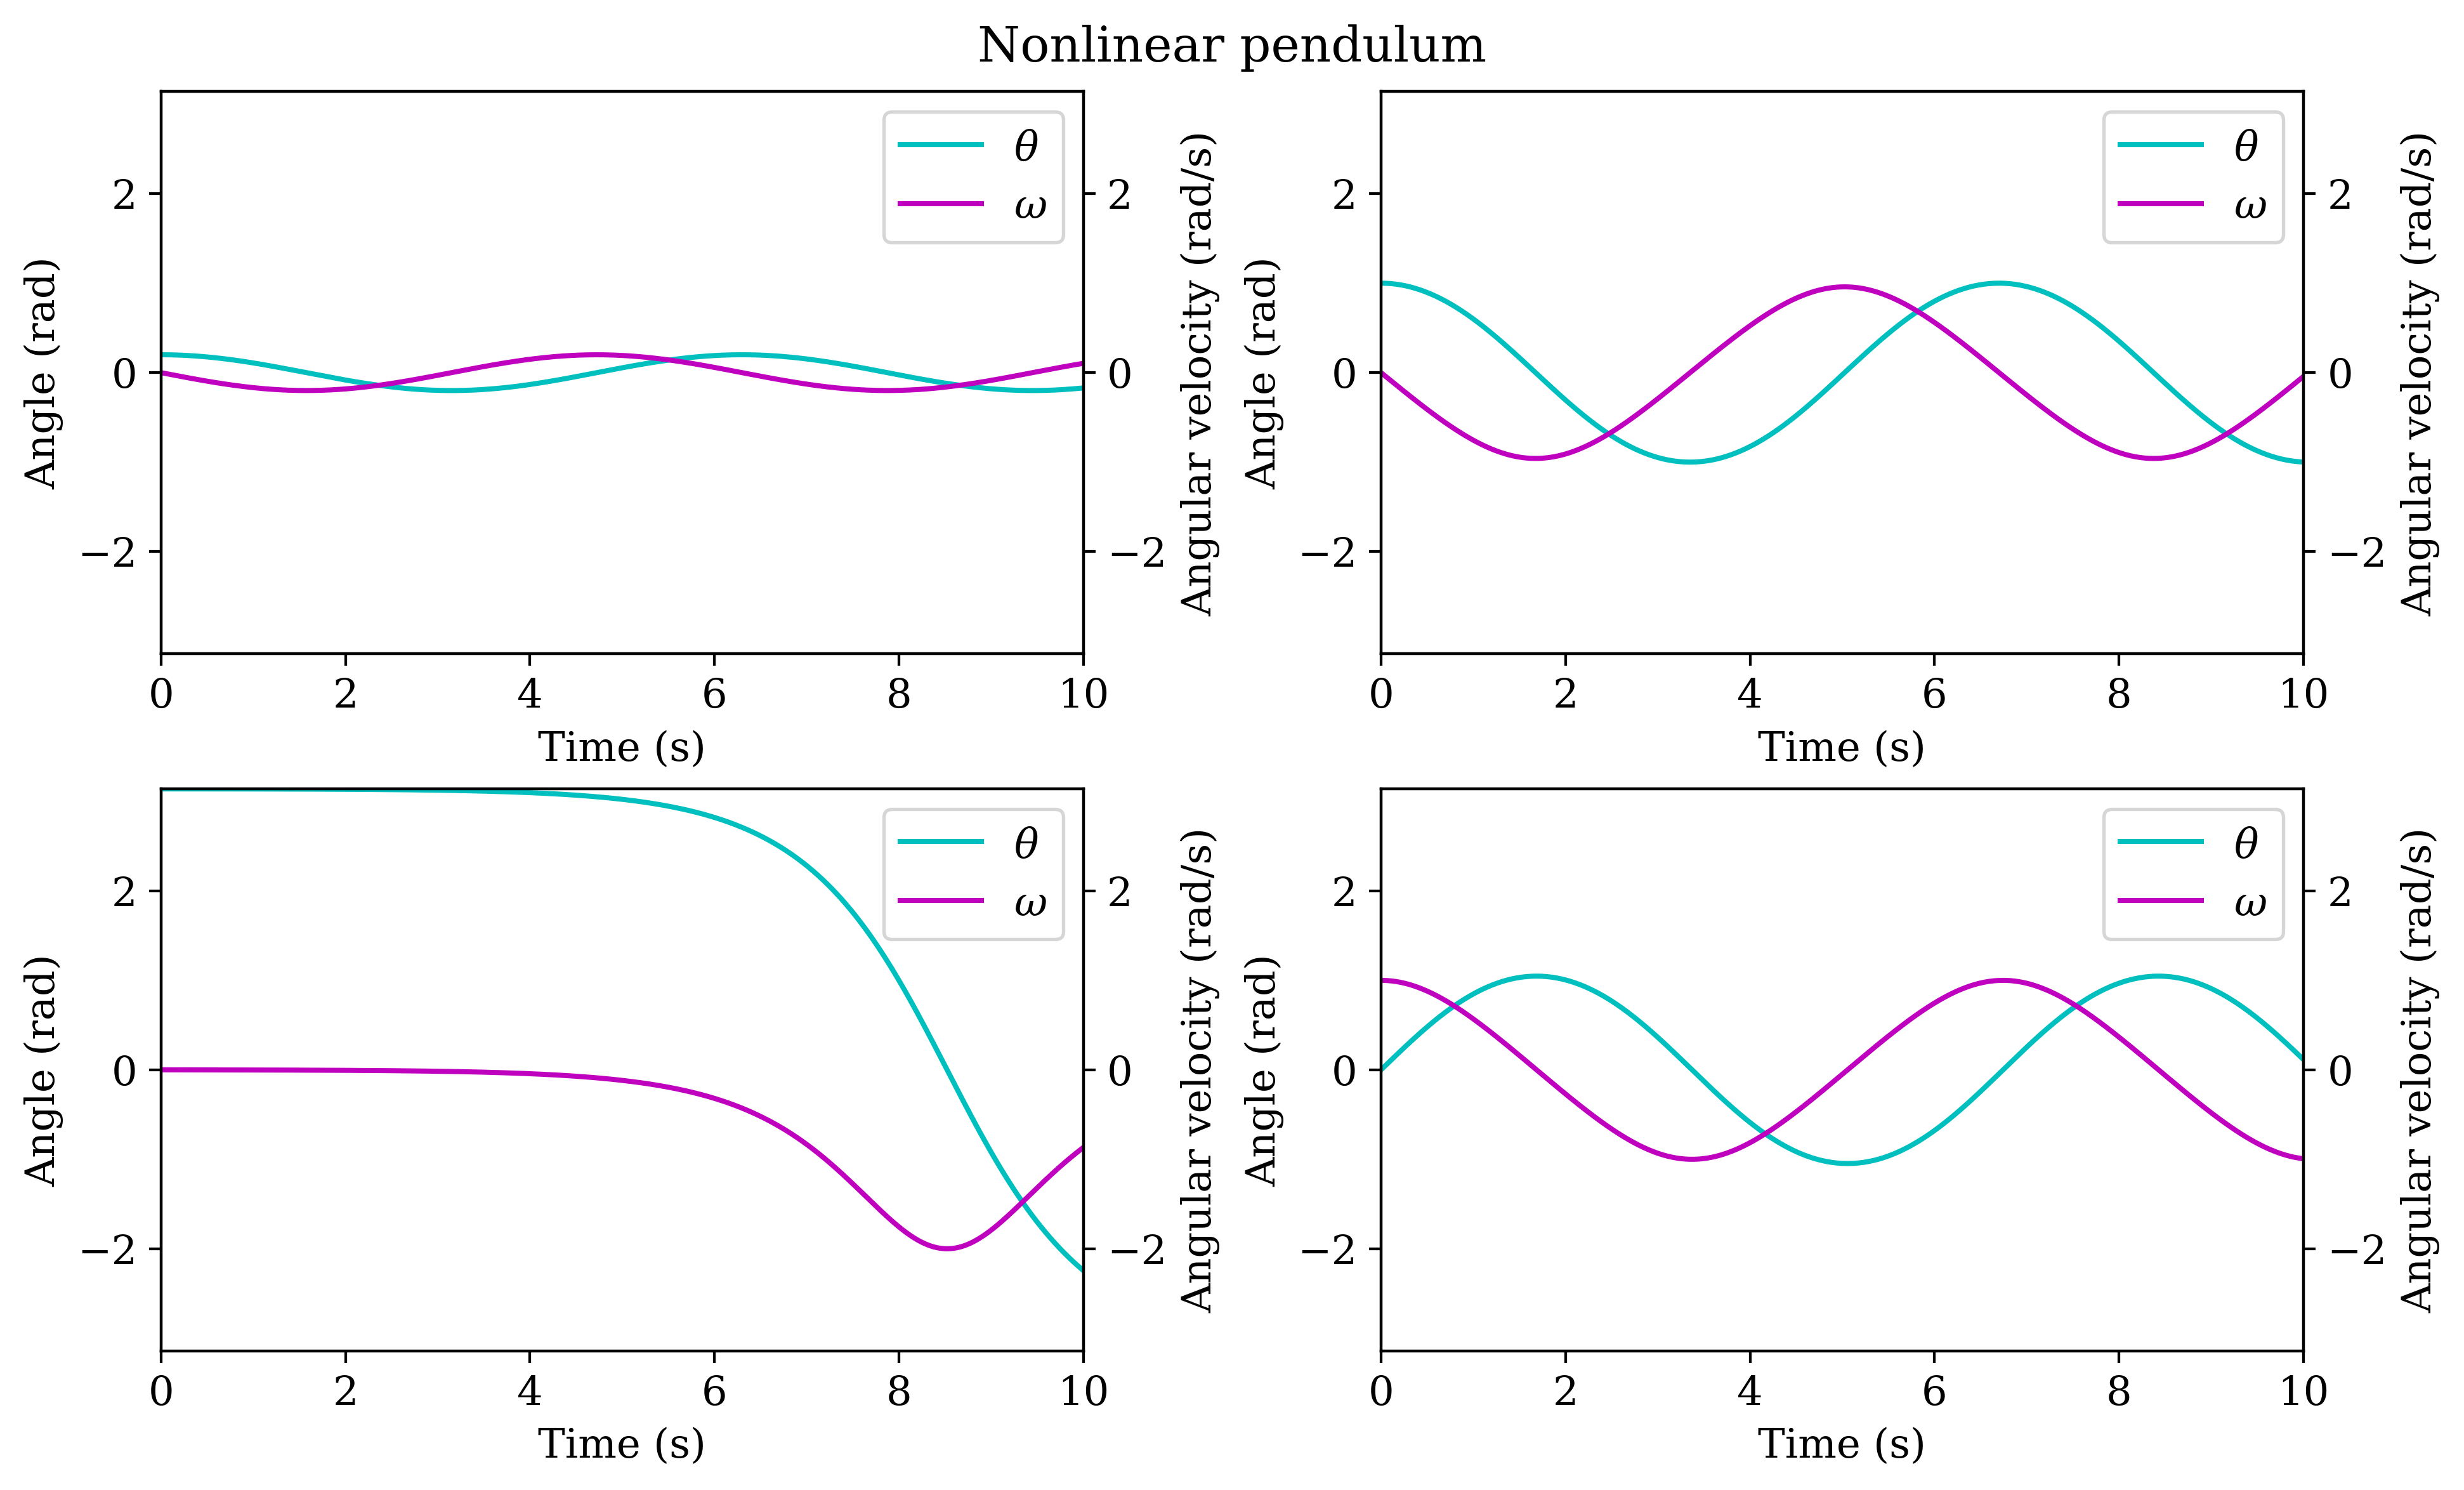

In [4]:
"""Equation of motion for a nonlinear pendulum
where inertial term equals 1

f(θ, ω, t) = - sin(θ) - k * ω + A * cos(ϕ * t)
"""
def nonlinear_f(theta, omega, t, **kwargs):

  k = kwargs.get('k', 0.0)
  phi = kwargs.get('phi', 0.66667)
  A = kwargs.get('A', 0.0)

  return -np.sin(theta) - k * omega + A * np.cos(phi * t)


fig, axs = plt.subplots(2, 2, figsize=(10, 6), constrained_layout=True,
                        dpi=384)
fig.suptitle('Nonlinear pendulum')

for theta, omega, ax in zip(initial_theta, initial_omega, axs.flat):

  thetas, omegas, nsteps = swing(theta, omega, f=nonlinear_f)

  plot(ax, time(nsteps), thetas, omegas, xlim=(0,10), yax2=True)

plt.savefig('nonlinear_pendulum.png', bbox_inches='tight')
plt.show()

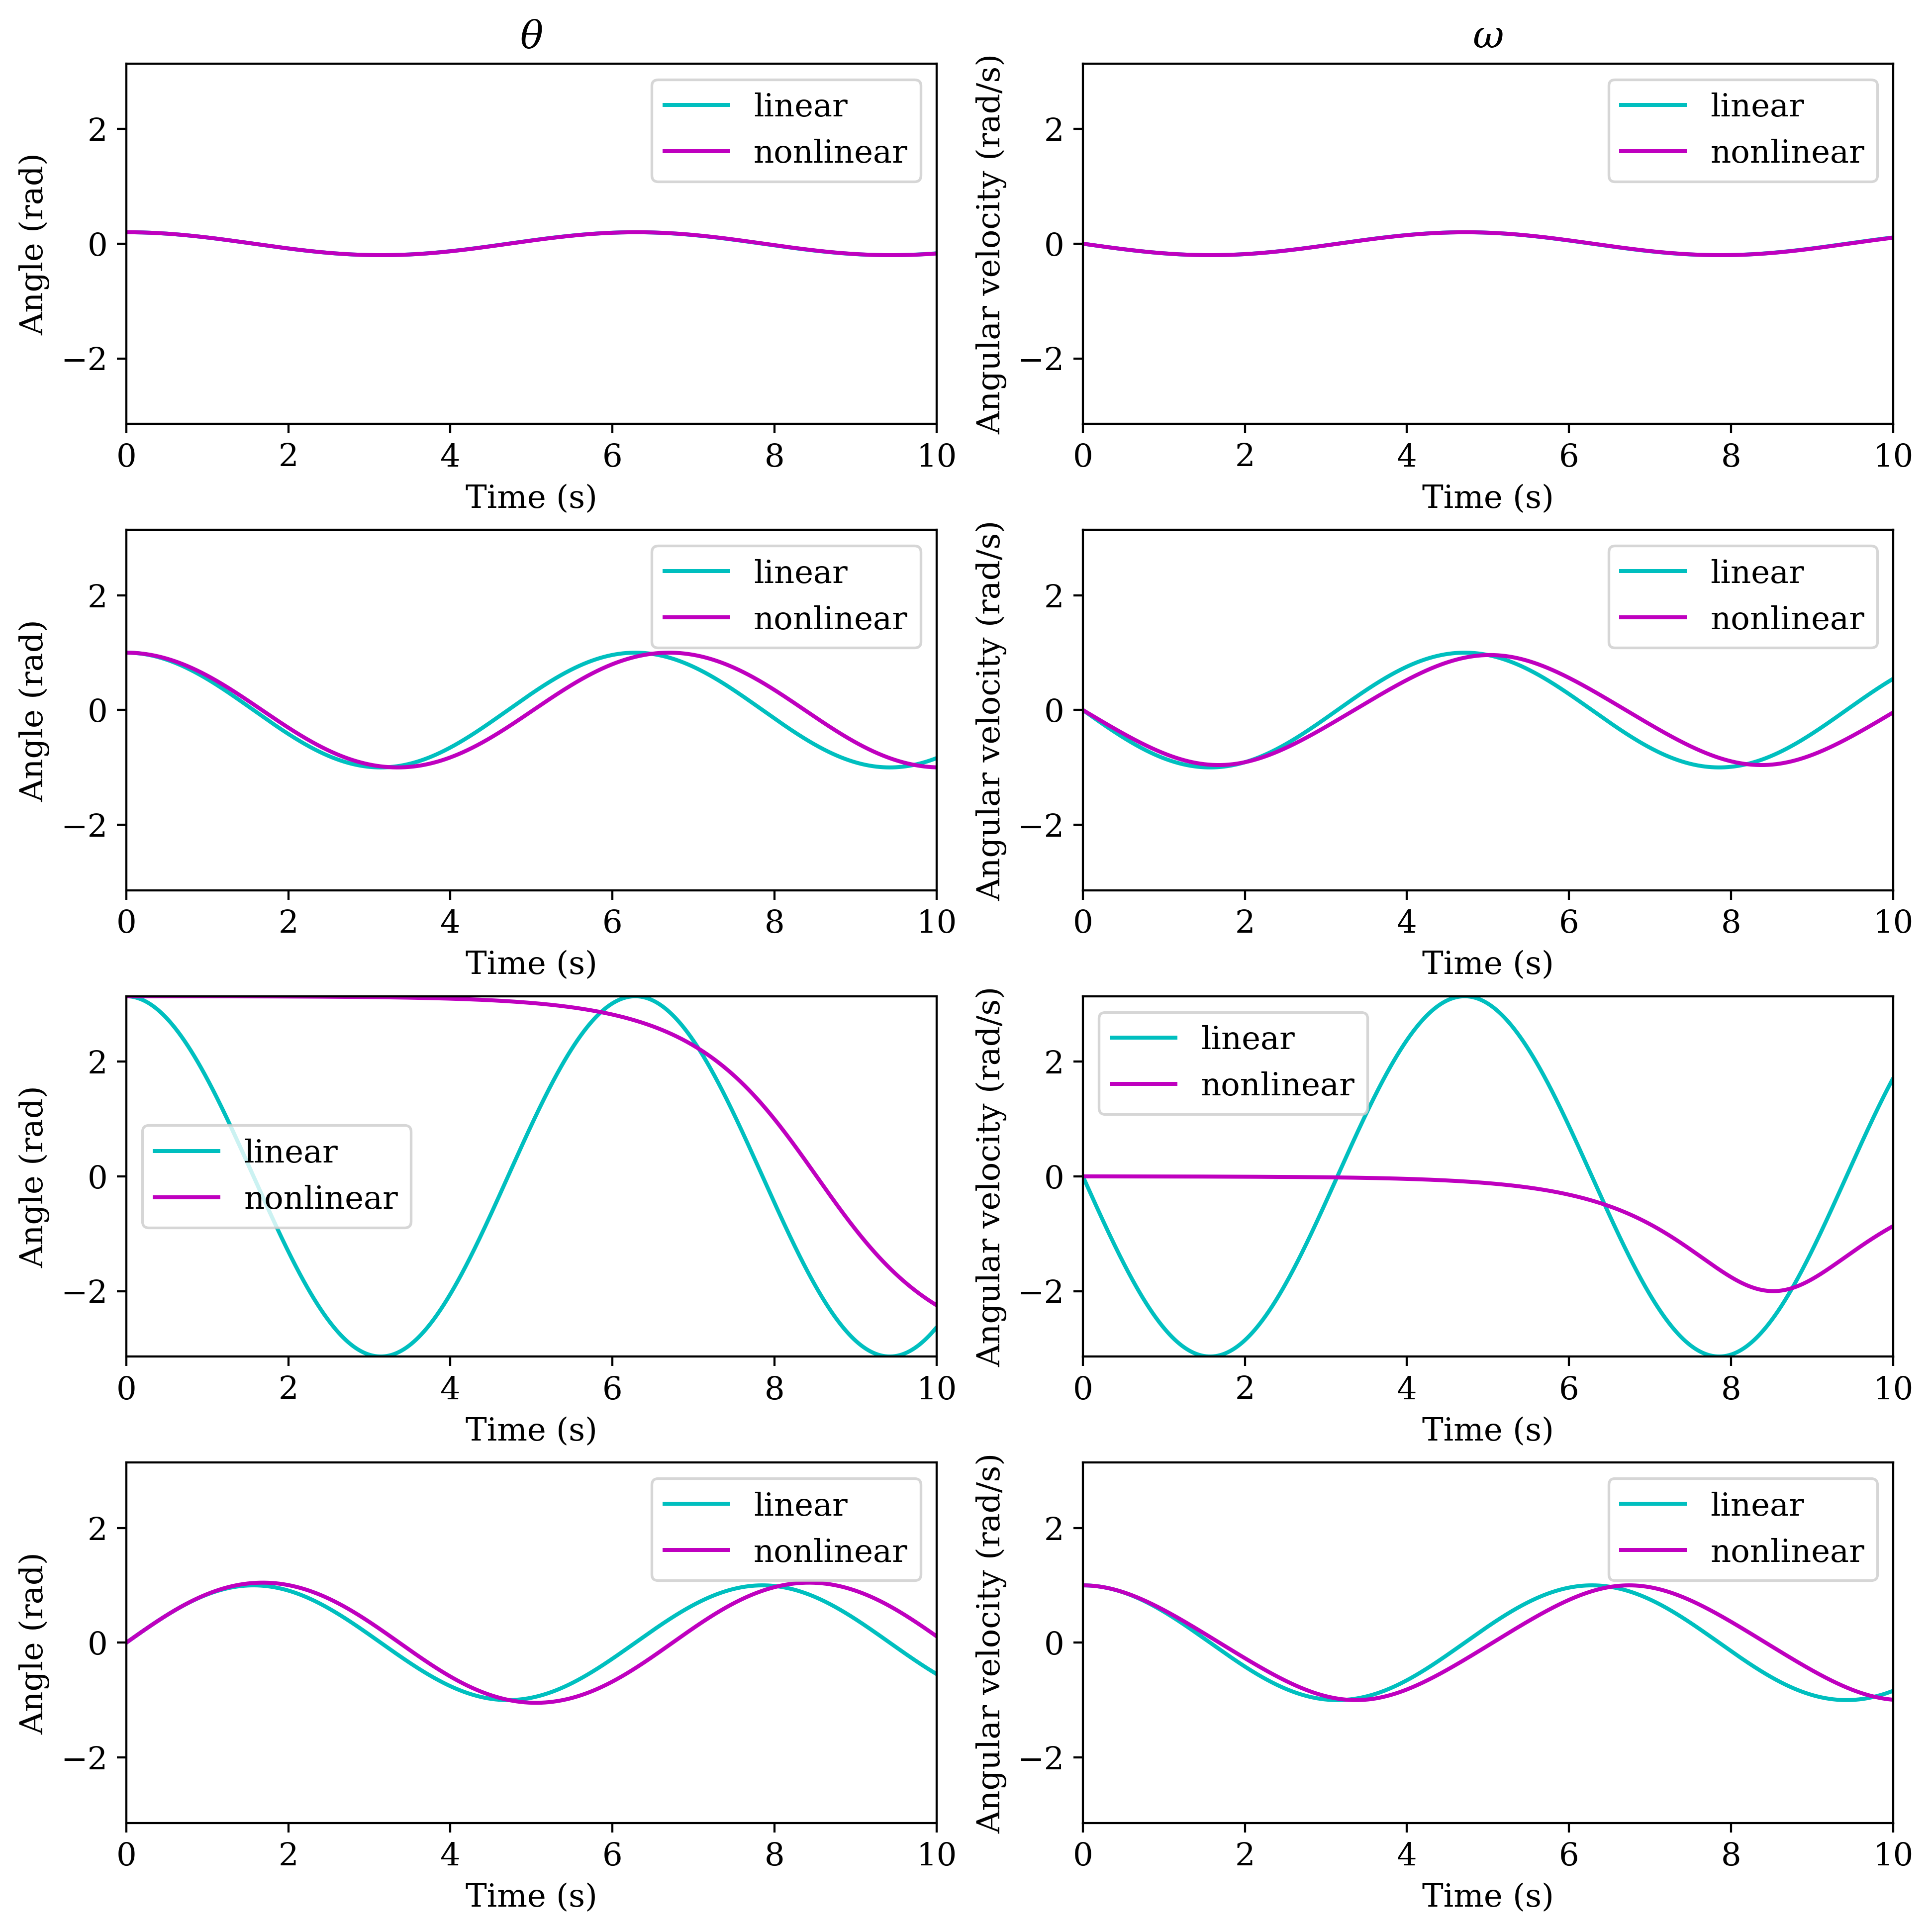

In [5]:
fig, axs = plt.subplots(4, 2, figsize=(10, 10), constrained_layout=True,
                        dpi=384)

for theta, omega, ax in zip(initial_theta, initial_omega, axs):

  l_thetas, l_omegas, nsteps = swing(theta, omega)
  n_thetas, n_omegas, _ = swing(theta, omega, f=nonlinear_f)

  plot(ax[0], time(nsteps), l_thetas, n_thetas,
       labels=['linear', 'nonlinear'], xlim=(0,10))

  plot(ax[1], time(nsteps), l_omegas, n_omegas,
       labels=['linear', 'nonlinear'], xlim=(0,10),
       ylabel='Angular velocity (rad/s)')

axs[0,0].set_title('$θ$')
axs[0,1].set_title('$ω$')
plt.savefig('linear_vs_nonlinear.png', bbox_inches='tight')
plt.show()

# Exercise 3

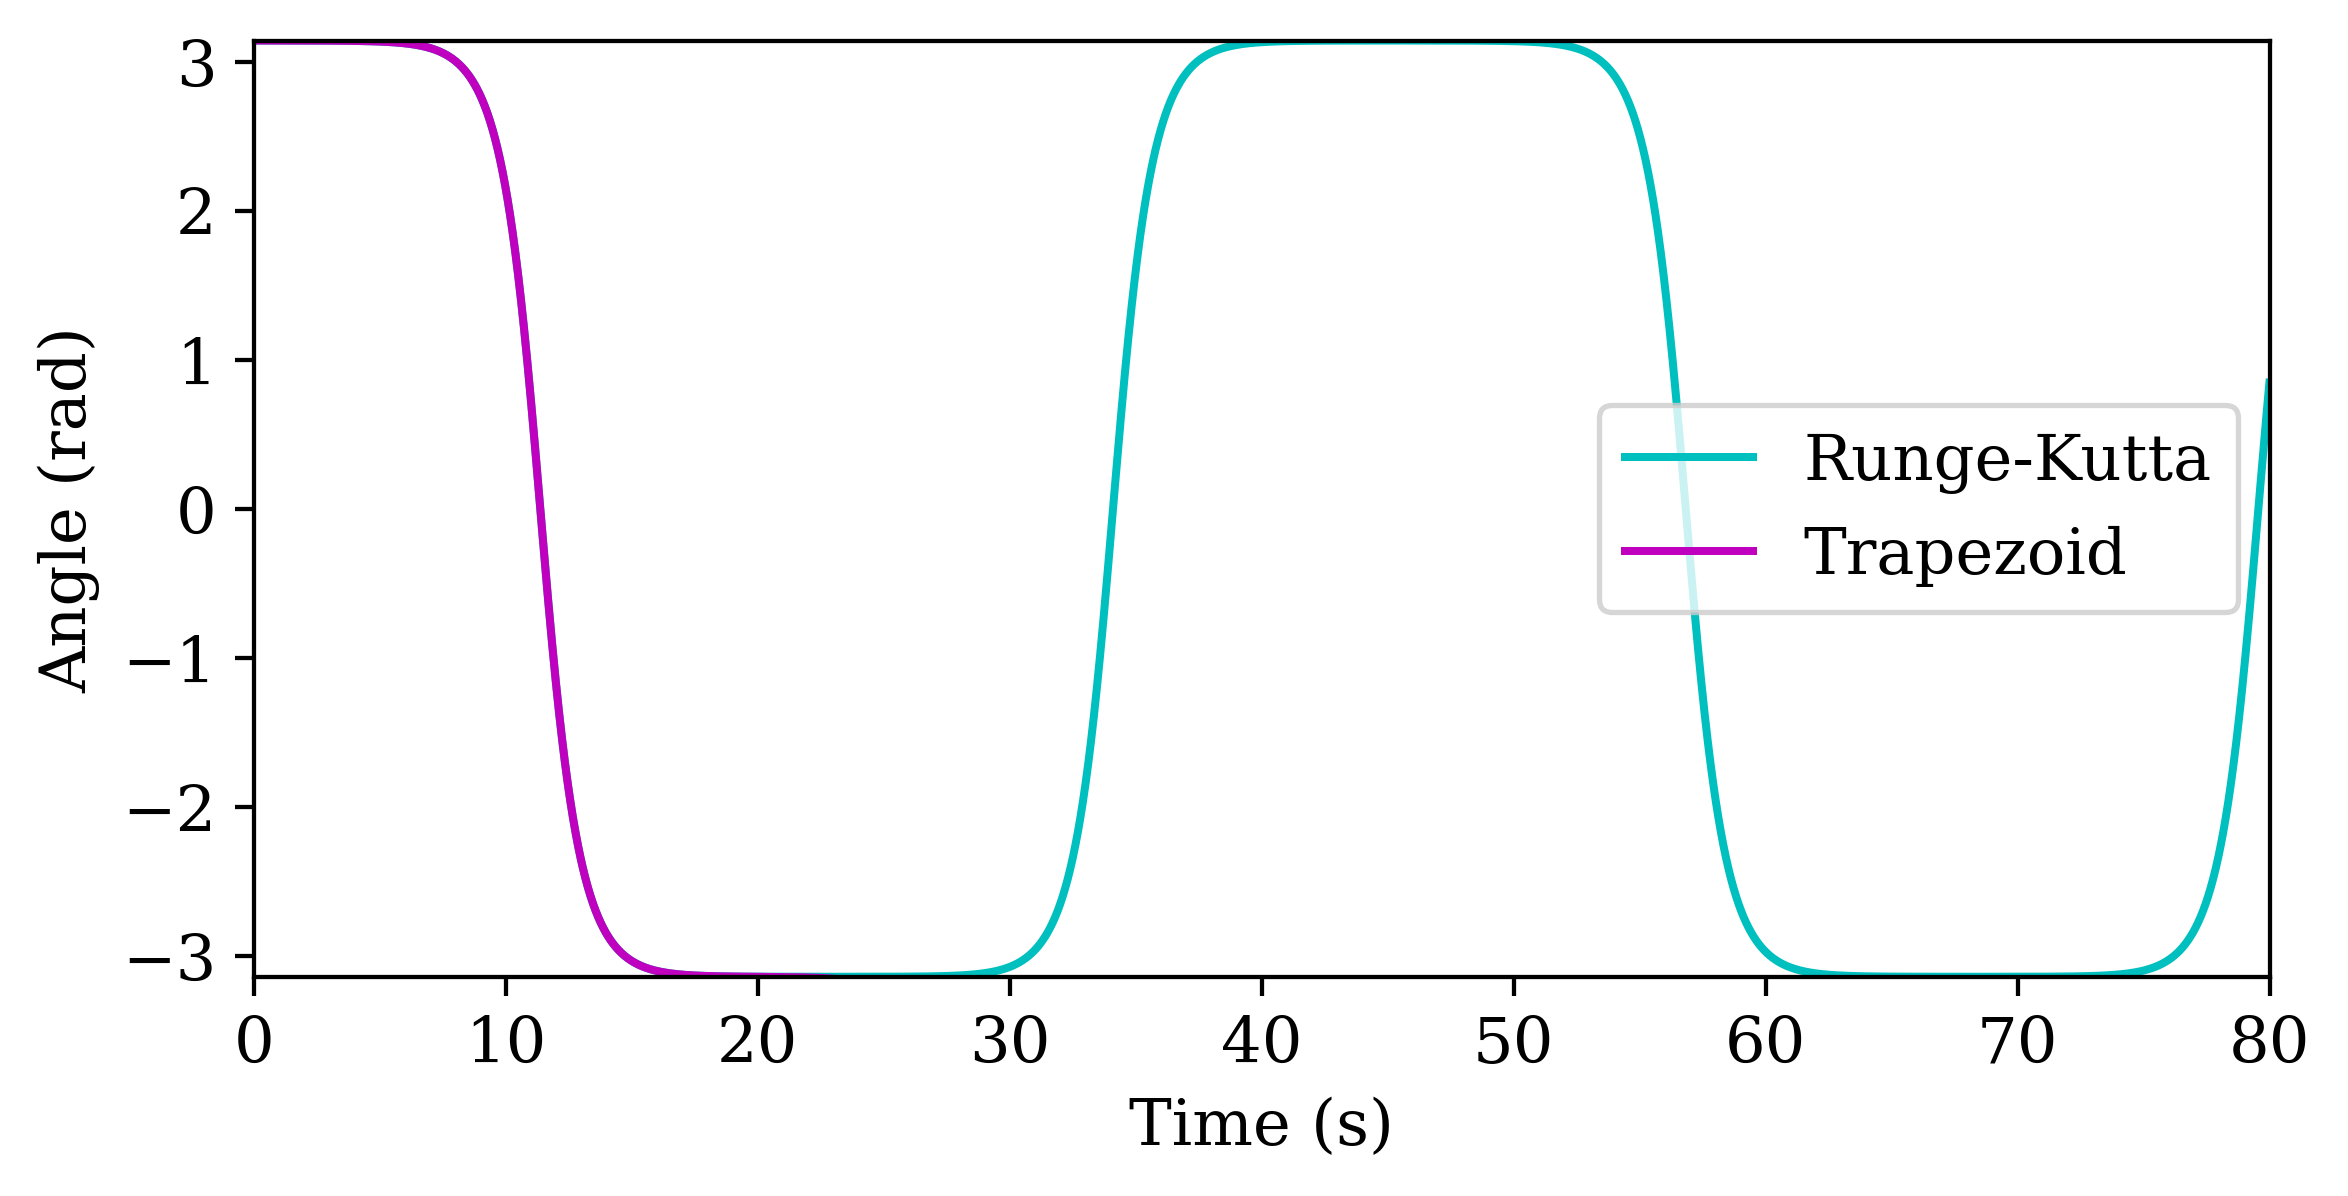

In [6]:
"""Runge-Kutta method for solving ODEs

For more information see:
https://en.wikipedia.org/wiki/Runge%E2%80%93Kutta_methods
"""
def runge_kutta(theta, omega, t, **kwargs):

  f = kwargs.get('f', nonlinear_f)

  k1a = dt * omega
  k1b = dt * f(theta, omega, t, **kwargs)

  k2a = dt * (omega + k1b/2)
  k2b = dt * f(theta + k1a/2, omega + k1b/2, t + dt/2, **kwargs)

  k3a = dt * (omega + k2b/2)
  k3b = dt * f(theta + k2a/2, omega + k2b/2, t + dt/2, **kwargs)

  k4a = dt * (omega + k3b)
  k4b = dt * f(theta + k3a, omega + k3b, t + dt, **kwargs)

  theta += (k1a + 2 * k2a + 2 * k3a + k4a) / 6
  omega += (k1b + 2 * k2b + 2 * k3b + k4b) / 6
  t += dt

  if kwargs.get('angle_wrap', False):
    theta = limit(theta, kwargs.get('shift', 0.0))

  return theta, omega, t


theta = 3.1415
omega = 0.0

thetas, _, nsteps = swing(theta, omega, f=nonlinear_f, nsteps=8000)
thetas_rk, _, _ = swing(theta, omega, integration=runge_kutta,
                        nsteps=8000)

fig, ax = plt.subplots(figsize=(6, 3), constrained_layout=True, dpi=384)

plot(ax, time(nsteps), thetas_rk, thetas,
     labels=['Runge-Kutta', 'Trapezoid'], xlim=(0,80))

plt.savefig('integration.png', bbox_inches='tight')
plt.show()

# Exercise 4

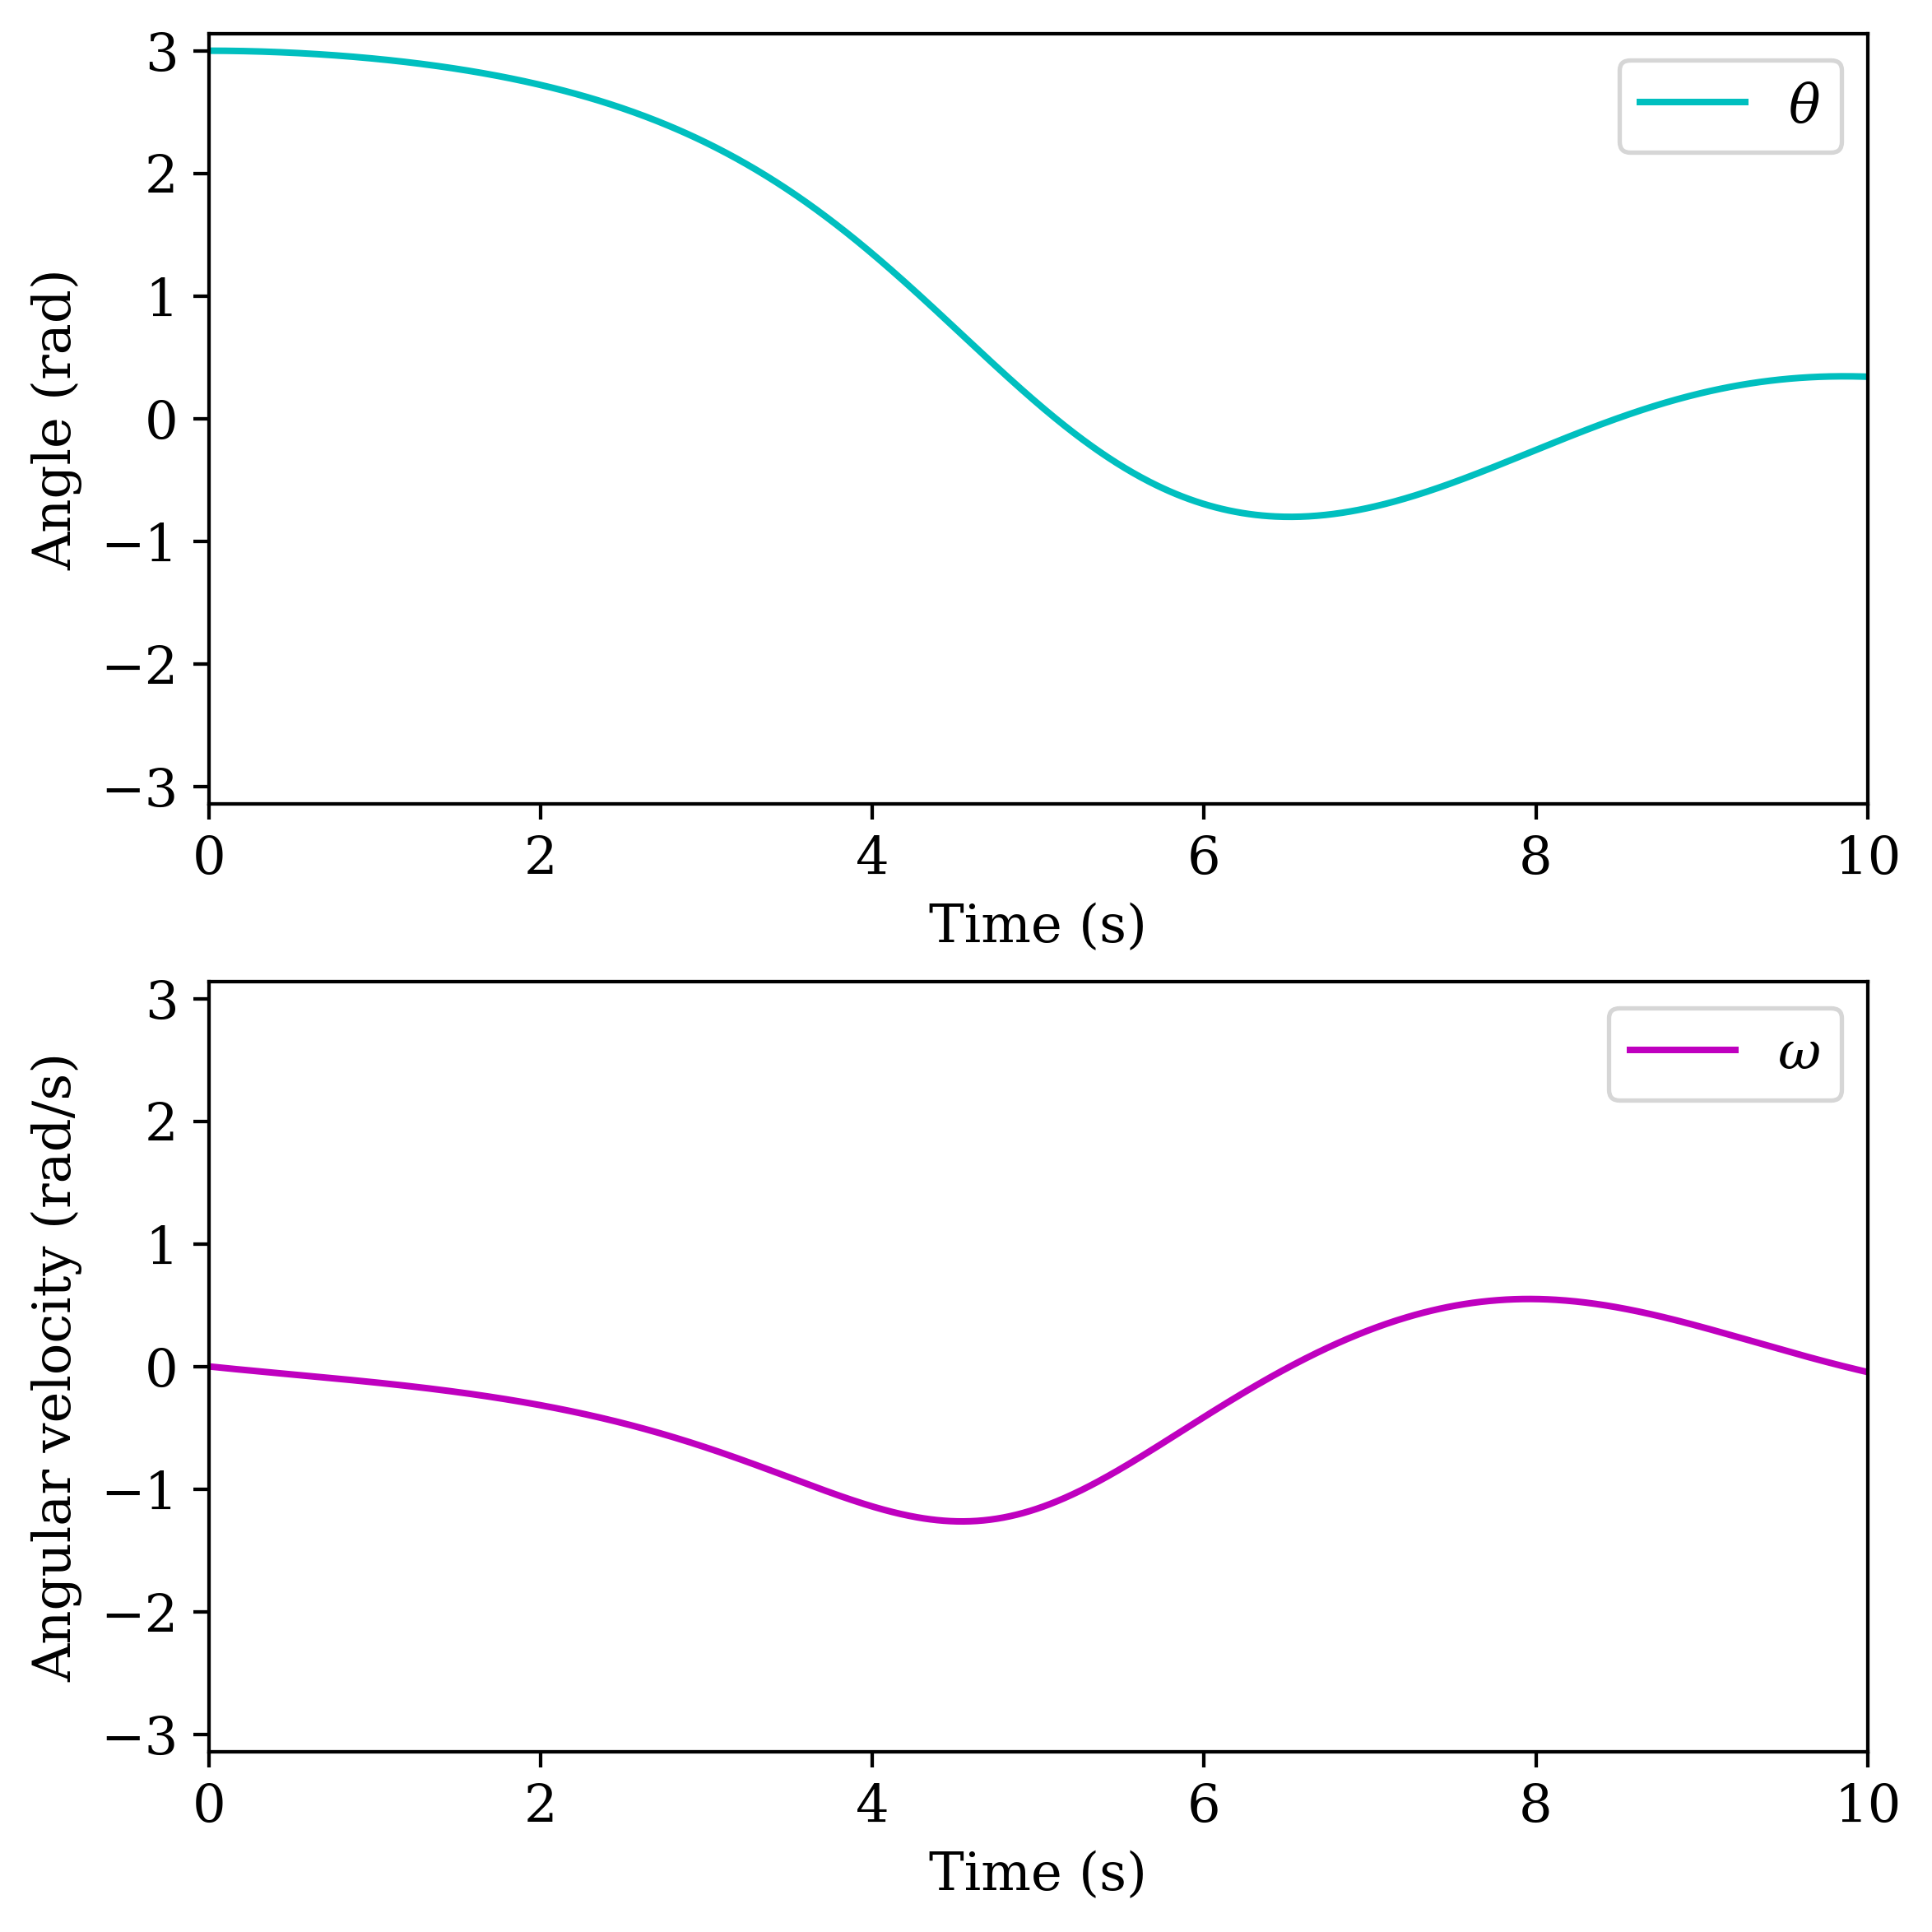

In [7]:
theta = 3.0
omega = 0.0

thetas, omegas, nsteps = swing(theta, omega, k=0.5,
                               integration=runge_kutta)

fig, axs = plt.subplots(2, 1, figsize=(6, 6), constrained_layout=True,
                        dpi=384)

plot(axs[0], time(nsteps), thetas, xlim=(0,10), ylim=(-np.pi,np.pi))

plot(axs[1], time(nsteps), omegas, labels=['$ω$'], cs=['m'], xlim=(0,10),
     ylabel='Angular velocity (rad/s)')

plt.savefig('damped.png', bbox_inches='tight')
plt.show()

# Exercise 5

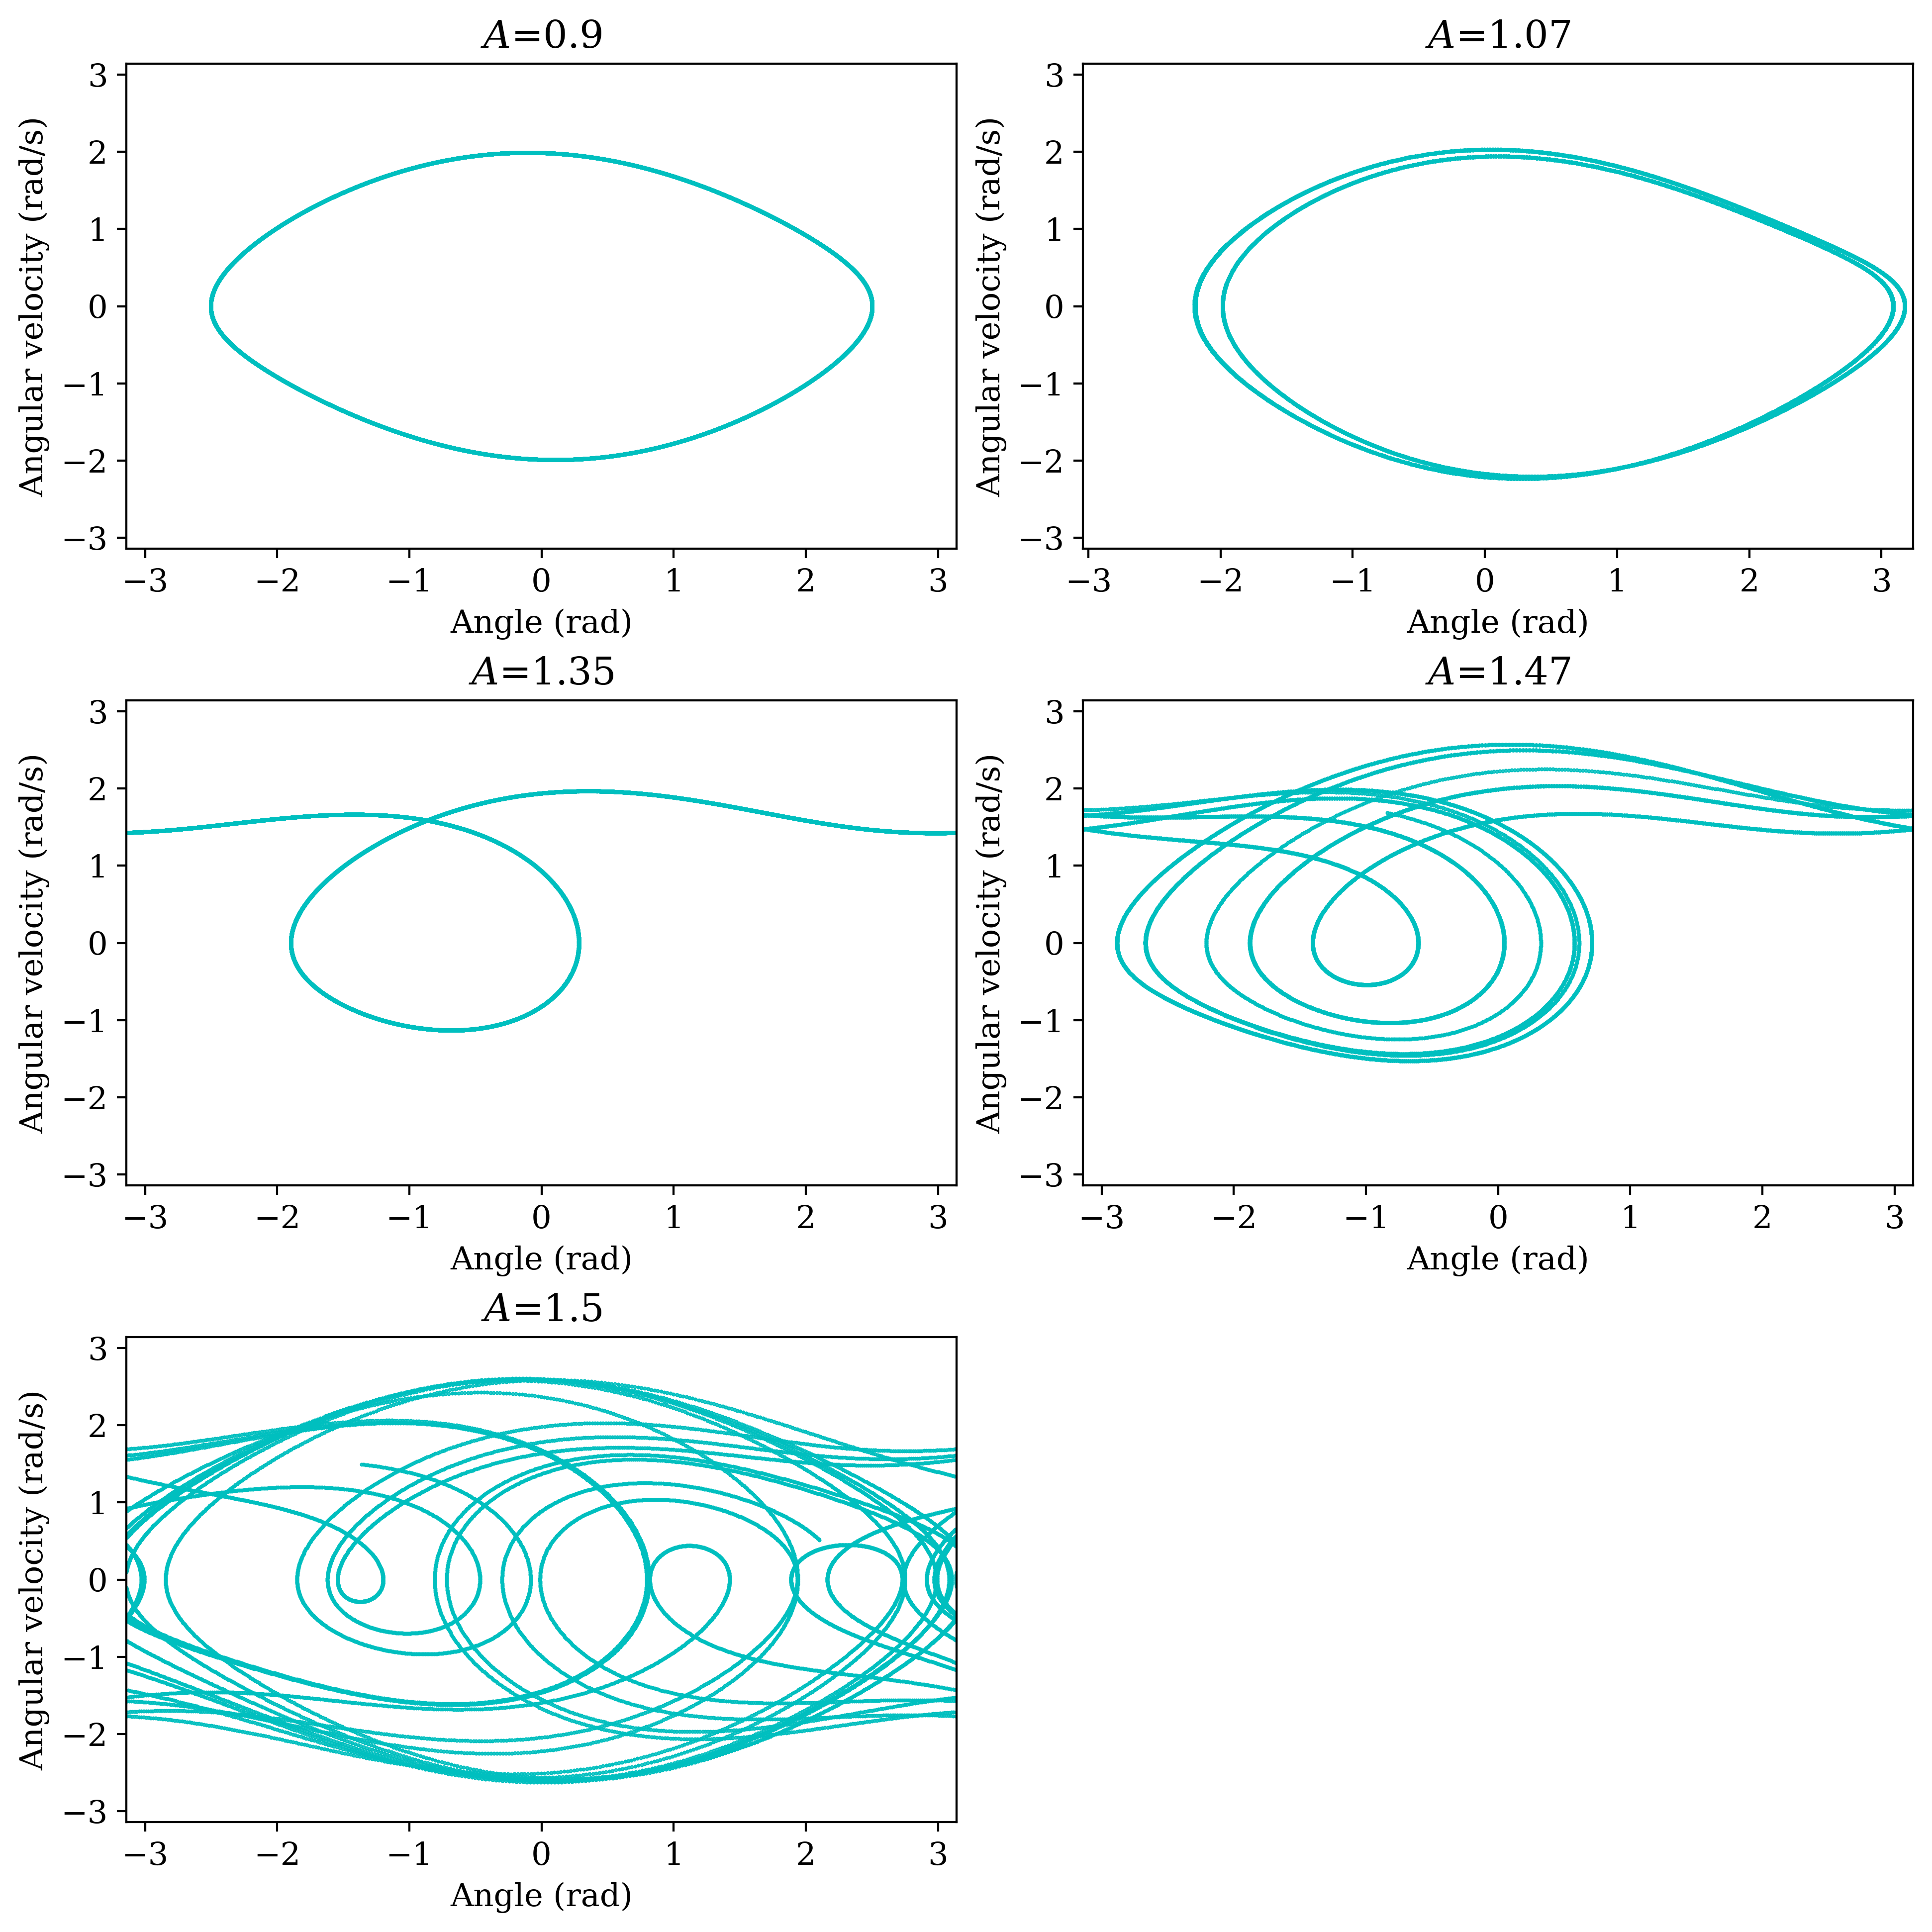

In [8]:
As = [0.9, 1.07, 1.35, 1.47, 1.5]
shifts = [0.0, 0.1, 0.0, 0.0, 0.0]
transient = 5000

fig, axs = plt.subplots(3, 2, figsize=(10, 10), constrained_layout=True,
                        dpi=384)

for A, shift, ax in zip(As, shifts, axs.flat):
  thetas, omegas, _ = swing(theta, omega, A=A, k=0.5,
                            integration=runge_kutta, angle_wrap=True,
                            nsteps=20000, shift=shift)

  plot(ax, thetas[transient:], omegas[transient:], title=f'$A$={A}',
       xlabel='Angle (rad)', ylabel='Angular velocity (rad/s)', cs=['c.'],
       legend=False, xlim=(-np.pi+shift, np.pi+shift))

fig.delaxes(axs[2,1])
plt.savefig('portrait.png', bbox_inches='tight')
plt.show()